# Energy Model and Diffusion Model on CIFAR-10

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

torch.manual_seed(42)

device = (
    torch.device("mps")
    if torch.backends.mps.is_available()
    else torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
)
print(device)

mps


## model.py

In [2]:
class EnergyModel(nn.Module):
    """Maps a 3x32x32 image in [-1, 1] to a scalar energy (low = realistic)."""

    def __init__(self):
        super().__init__()
        # Swish (SiLU) is smooth, which Langevin sampling needs; no BatchNorm
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 5, stride=2, padding=2), nn.SiLU(),    # 16x16
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.SiLU(),   # 8x8
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.SiLU(),  # 4x4
            nn.Conv2d(128, 256, 3, stride=2, padding=1), nn.SiLU(),  # 2x2
            nn.Flatten(),
            nn.Linear(256 * 2 * 2, 64), nn.SiLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

In [3]:
def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(t_emb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class DiffusionUNet(nn.Module):
    """Small U-Net that predicts the noise added to an image at timestep t."""

    def __init__(self, base=64, t_dim=128):
        super().__init__()
        self.t_dim = t_dim
        self.t_mlp = nn.Sequential(nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.inp = nn.Conv2d(3, base, 3, padding=1)
        self.down1 = ResBlock(base, base, t_dim)            # 32x32
        self.down2 = ResBlock(base, base * 2, t_dim)        # 16x16
        self.mid = ResBlock(base * 2, base * 2, t_dim)      # 8x8
        self.up2 = ResBlock(base * 4, base, t_dim)          # 16x16
        self.up1 = ResBlock(base * 2, base, t_dim)          # 32x32
        self.out = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 3, 3, padding=1))
        self.pool = nn.AvgPool2d(2)
        self.upsample = nn.Upsample(scale_factor=2, mode="nearest")

    def forward(self, x, t):
        t_emb = self.t_mlp(timestep_embedding(t, self.t_dim))
        x = self.inp(x)
        d1 = self.down1(x, t_emb)
        d2 = self.down2(self.pool(d1), t_emb)
        m = self.mid(self.pool(d2), t_emb)
        u2 = self.up2(torch.cat([self.upsample(m), d2], dim=1), t_emb)
        u1 = self.up1(torch.cat([self.upsample(u2), d1], dim=1), t_emb)
        return self.out(u1)


class DiffusionModel(nn.Module):
    """DDPM: linear beta schedule, noise-prediction U-Net, ancestral sampling."""

    def __init__(self, timesteps=200, beta_start=1e-4, beta_end=0.02):
        super().__init__()
        self.timesteps = timesteps
        self.unet = DiffusionUNet()
        betas = torch.linspace(beta_start, beta_end, timesteps)
        alphas = 1.0 - betas
        alphas_bar = torch.cumprod(alphas, dim=0)
        self.register_buffer("betas", betas)
        self.register_buffer("alphas", alphas)
        self.register_buffer("alphas_bar", alphas_bar)

    def forward(self, x, t):
        return self.unet(x, t)

    def loss(self, x0):
        t = torch.randint(0, self.timesteps, (x0.size(0),), device=x0.device)
        noise = torch.randn_like(x0)
        ab = self.alphas_bar[t][:, None, None, None]
        xt = ab.sqrt() * x0 + (1 - ab).sqrt() * noise
        return F.mse_loss(self.unet(xt, t), noise)

    @torch.no_grad()
    def sample(self, num_samples, device="cpu"):
        x = torch.randn(num_samples, 3, 32, 32, device=device)
        for i in reversed(range(self.timesteps)):
            t = torch.full((num_samples,), i, device=device, dtype=torch.long)
            eps = self.unet(x, t)
            alpha, ab, beta = self.alphas[i], self.alphas_bar[i], self.betas[i]
            x = (x - beta / (1 - ab).sqrt() * eps) / alpha.sqrt()
            if i > 0:
                x = x + beta.sqrt() * torch.randn_like(x)
        return x.clamp(-1, 1)

## trainer.py

In [4]:
def train_energy(model, data_loader, optimizer, device='cpu', epochs=10, alpha=0.1,
                 langevin_steps=60, buffer_size=8192):
    # Contrastive divergence: push energy down on real images, up on samples
    # drawn from the model by Langevin dynamics. A replay buffer keeps the
    # chains persistent so they can get further from noise over training.
    model.to(device).train()
    buffer = torch.rand(buffer_size, 3, 32, 32) * 2 - 1
    for epoch in range(epochs):
        total = 0.0
        for real, _ in data_loader:
            real = real.to(device) + 0.005 * torch.randn_like(real.to(device))
            bs = real.size(0)

            # 5% fresh noise, the rest from the buffer
            idx = torch.randint(0, buffer_size, (bs,))
            start = buffer[idx].clone()
            fresh = torch.rand(bs) < 0.05
            start[fresh] = torch.rand(int(fresh.sum()), 3, 32, 32) * 2 - 1
            fake = langevin_sample(model, start.to(device), steps=langevin_steps)
            buffer[idx] = fake.cpu()

            model.train()
            e_real, e_fake = model(real), model(fake)
            # alpha term keeps energies bounded so training stays stable
            loss = (e_real - e_fake).mean() + alpha * (e_real ** 2 + e_fake ** 2).mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
        print(f"Epoch {epoch+1}/{epochs}  Loss: {total / len(data_loader):.4f}  "
              f"E(real): {e_real.mean().item():.3f}  E(fake): {e_fake.mean().item():.3f}")
    return model


def train_diffusion(model, data_loader, optimizer, device='cpu', epochs=10):
    model.to(device).train()
    for epoch in range(epochs):
        running_loss = 0.0
        for real, _ in data_loader:
            loss = model.loss(real.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"Epoch {epoch+1}/{epochs}  Loss: {running_loss / len(data_loader):.4f}")
    return model

## generator.py

In [5]:
def langevin_sample(model, x, steps=60, step_size=10.0, noise=0.005):
    # Gradient descent on the energy, with a little noise at each step
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    x = x.clone().requires_grad_(True)
    for _ in range(steps):
        x.data.add_(noise * torch.randn_like(x))
        x.data.clamp_(-1, 1)
        grad = torch.autograd.grad(model(x).sum(), x)[0]
        x.data.add_(-step_size * grad)
        x.data.clamp_(-1, 1)
    for p in model.parameters():
        p.requires_grad_(True)
    return x.detach()


def show_samples(images, title):
    images = ((images.cpu() + 1) / 2).clamp(0, 1)
    fig, axes = plt.subplots(1, len(images), figsize=(len(images) * 2, 2.4))
    for ax, img in zip(axes, images):
        ax.imshow(img.permute(1, 2, 0))
        ax.axis("off")
    fig.suptitle(title)
    plt.show()

## Load CIFAR-10

In [6]:
# scaled to [-1, 1] to match the models
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, drop_last=True)

## Train the energy model

In [7]:
energy_model = EnergyModel()
opt = optim.Adam(energy_model.parameters(), lr=1e-4, betas=(0.0, 0.999))
energy_model = train_energy(energy_model, train_loader, opt, device=device, epochs=5)

Epoch 1/5  Loss: -0.0069  E(real): -0.007  E(fake): -0.010


Epoch 2/5  Loss: -0.0008  E(real): -0.005  E(fake): -0.007


Epoch 3/5  Loss: 0.0001  E(real): 0.001  E(fake): 0.005


Epoch 4/5  Loss: -0.0002  E(real): -0.014  E(fake): -0.008


Epoch 5/5  Loss: 0.0005  E(real): 0.000  E(fake): -0.003


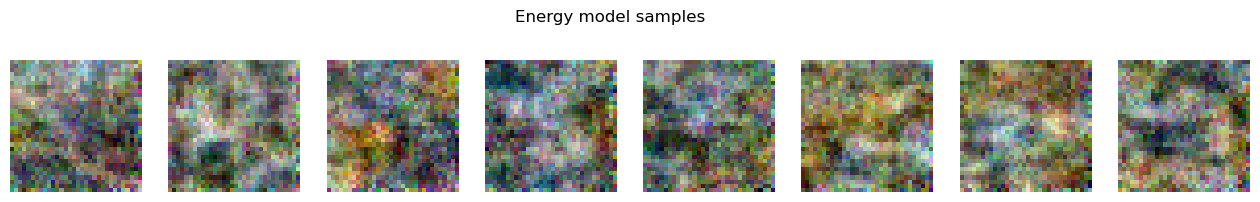

In [8]:
energy_model.to(device)
start = torch.rand(8, 3, 32, 32, device=device) * 2 - 1
show_samples(langevin_sample(energy_model, start, steps=200), "Energy model samples")

## Train the diffusion model

In [9]:
diffusion_model = DiffusionModel()
opt = optim.Adam(diffusion_model.parameters(), lr=2e-4)
diffusion_model = train_diffusion(diffusion_model, train_loader, opt, device=device, epochs=10)

Epoch 1/10  Loss: 0.1678


Epoch 2/10  Loss: 0.0997


Epoch 3/10  Loss: 0.0918


Epoch 4/10  Loss: 0.0870


Epoch 5/10  Loss: 0.0865


Epoch 6/10  Loss: 0.0833


Epoch 7/10  Loss: 0.0827


Epoch 8/10  Loss: 0.0804


Epoch 9/10  Loss: 0.0803


Epoch 10/10  Loss: 0.0780


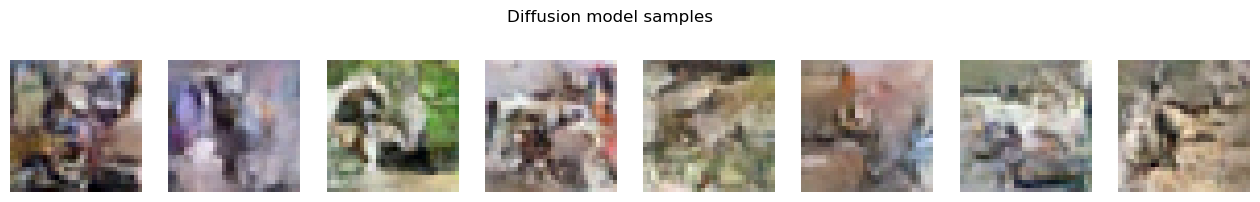

In [10]:
show_samples(diffusion_model.sample(8, device).cpu(), "Diffusion model samples")

## Save the models for the API

In [11]:
torch.save(energy_model.cpu().state_dict(), "gentext-app/app/energy_cifar10.pt")
torch.save(diffusion_model.cpu().state_dict(), "gentext-app/app/diffusion_cifar10.pt")